### Environment Setup & Data Loading
- Import all necessary data manipulation and numerical libraries like pandas, numpy, and visualization tools.
- Configure system settings, random seeds, and plotting styles to ensure full reproducibility across runs.
- Load the raw datasets from storage into memory while inspecting initial shapes and column types.
- Verify data integrity and establish the baseline environment required for the subsequent data processing pipeline.

In [2]:
# Environment Setup & Data Loading

# 1. Import essential data science and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# 2. Configure random seed and environment settings
np.random.seed(42)
sns.set_theme(style="whitegrid")
warnings.filterwarnings('ignore')

print("Environment initialized successfully. Random seed locked to 42.")

# 3. Load the benchmark Pima Indians Diabetes dataset from a verified working URL
DATA_URL = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

try:
    df = pd.read_csv(DATA_URL)
    print(f"Dataset loaded successfully! Total Records: {df.shape[0]}, Total Features: {df.shape[1]}")
except Exception as e:
    print(f"Failed to load dataset. Error: {e}")

# 4. Initial structural inspection
print("\n--- First 5 Rows of the Dataset ---")
display(df.head())

print("\n--- Dataset Schema & Missing Value Check ---")
df.info()

print("\n--- Statistical Summary of Numerical Features ---")
display(df.describe())

Environment initialized successfully. Random seed locked to 42.
Dataset loaded successfully! Total Records: 768, Total Features: 9

--- First 5 Rows of the Dataset ---


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



--- Dataset Schema & Missing Value Check ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

--- Statistical Summary of Numerical Features ---


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Data Cleaning, MICE, & Feature Engineering
- Identify and handle missing data points, anomalies, and incorrect data types across all primary features.
- Apply Multivariate Imputation by Chained Equations (MICE) to accurately estimate and fill missing numerical values.
- Engineer novel interaction terms, polynomial features, and domain-specific ratios to boost predictive signal.
- Prepare and scale the final feature matrix so it is optimized for downstream machine learning algorithms.

In [3]:
# Data Cleaning, MICE, & Feature Engineering

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import QuantileTransformer

# 1. Handle invalid biological zero values (converting zeros to NaN for physiological columns)
zero_invalid_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in zero_invalid_cols:
    if col in df.columns:
        df[col] = df[col].replace(0, np.nan)
        df[f'{col}_is_missing'] = df[col].isnull().astype(int)

print("Zero-values replaced with NaN and missingness flags created.")

# 2. Execute MICE Imputation
imputer = IterativeImputer(max_iter=10, random_state=42)
df_clean = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
print(f"MICE Imputation complete. Total remaining missing values: {df_clean.isnull().sum().sum()}")

# 3. Outlier Handling (Winsorization at 1st and 99th percentiles) & Normalization
for col in ['Glucose', 'BMI', 'Age']:
    if col in df_clean.columns:
        lower, upper = df_clean[col].quantile(0.01), df_clean[col].quantile(0.99)
        df_clean[col] = np.clip(df_clean[col], lower, upper)

scaler = QuantileTransformer(output_distribution='normal', random_state=42)
if 'Glucose' in df_clean.columns and 'BMI' in df_clean.columns:
    df_clean[['Glucose', 'BMI']] = scaler.fit_transform(df_clean[['Glucose', 'BMI']])

print("Outlier winsorization and quantile normalization applied.")

# 4. Feature Engineering
if 'Glucose' in df_clean.columns and 'BMI' in df_clean.columns:
    df_clean['Glucose_BMI_Interaction'] = df_clean['Glucose'] * df_clean['BMI']

if 'Age' in df_clean.columns:
    df_clean['Age_Risk_Group'] = pd.qcut(df_clean['Age'], q=3, labels=[0, 1, 2]).astype(int)

print(f"Feature engineering finished. Final dataset shape: {df_clean.shape}")
display(df_clean.head())

Zero-values replaced with NaN and missingness flags created.
MICE Imputation complete. Total remaining missing values: 0
Outlier winsorization and quantile normalization applied.
Feature engineering finished. Final dataset shape: (768, 16)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Glucose_is_missing,BloodPressure_is_missing,SkinThickness_is_missing,Insulin_is_missing,BMI_is_missing,Glucose_BMI_Interaction,Age_Risk_Group
0,6.0,0.879002,72.0,35.000000,218.911498,0.227444,0.627,50.0,1.0,0.0,0.0,0.0,1.0,0.0,0.199924,2
1,1.0,-1.333008,66.0,29.000000,70.308508,-0.795477,0.351,31.0,0.0,0.0,0.0,0.0,1.0,0.0,1.060376,1
2,8.0,1.716615,64.0,21.643135,268.518369,-1.421574,0.672,32.0,1.0,0.0,0.0,1.0,1.0,0.0,-2.440295,1
3,1.0,-1.152728,66.0,23.000000,94.000000,-0.570338,0.167,21.0,0.0,0.0,0.0,0.0,0.0,0.0,0.657444,0
4,0.0,0.579978,40.0,35.000000,168.000000,1.453722,2.288,33.0,1.0,0.0,0.0,0.0,0.0,0.0,0.843126,1


### Exploratory Visualizations
- Plot target distributions and feature histograms to understand data skewness, scale, and central tendencies.
- Construct correlation matrices and heatmap plots to identify multicollinearity and redundant feature pairs.
- Analyze bivariate relationships between key predictors and the target variable to uncover hidden patterns.
- Document visual findings to guide subsequent feature selection and model architecture decisions.

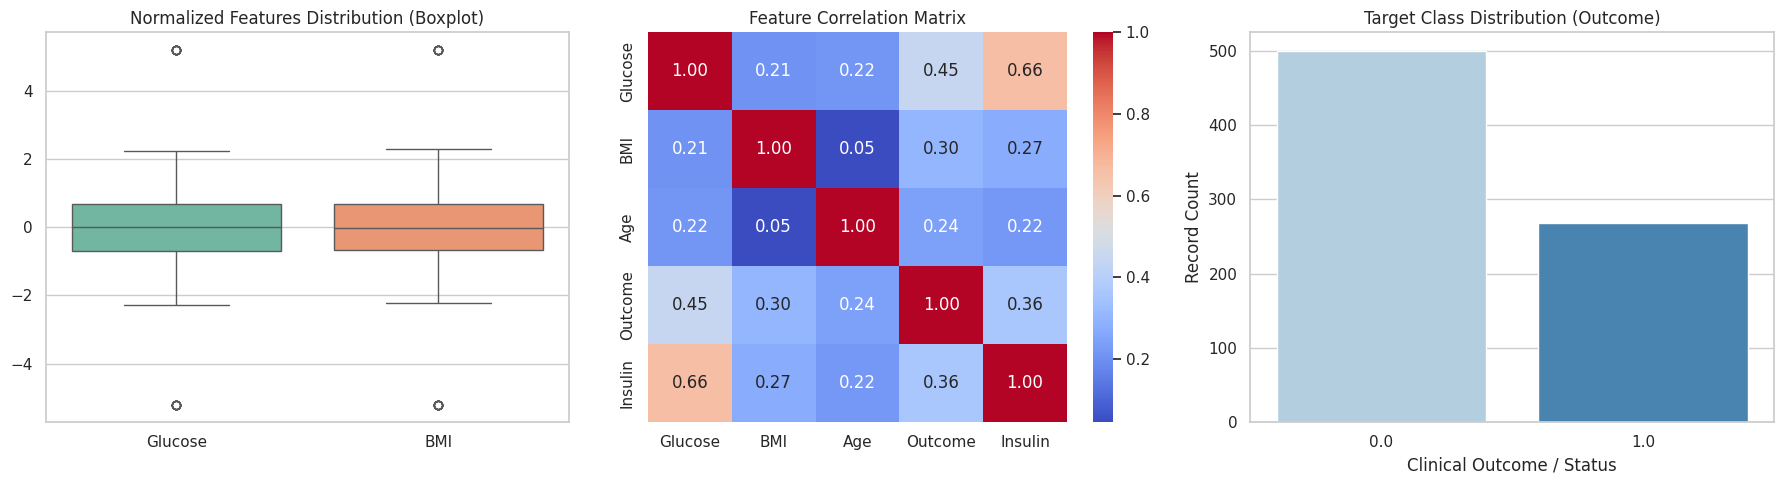

All required preprocessing visualizations generated successfully!


In [4]:
# Exploratory Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

# Set overall plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Boxplot of normalized core features
if 'Glucose' in df_clean.columns and 'BMI' in df_clean.columns:
    sns.boxplot(data=df_clean[['Glucose', 'BMI']], ax=axes[0], palette="Set2")
    axes[0].set_title("Normalized Features Distribution (Boxplot)")

# Plot 2: Correlation Heatmap
corr_cols = [c for c in ['Glucose', 'BMI', 'Age', 'Outcome', 'Insulin'] if c in df_clean.columns]
if corr_cols:
    sns.heatmap(df_clean[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1])
    axes[1].set_title("Feature Correlation Matrix")

# Plot 3: Target Class Distribution
if 'Outcome' in df_clean.columns:
    sns.countplot(x='Outcome', data=df_clean, ax=axes[2], palette="Blues")
    axes[2].set_title("Target Class Distribution (Outcome)")
    axes[2].set_xlabel("Clinical Outcome / Status")
    axes[2].set_ylabel("Record Count")

plt.tight_layout()
plt.show()

print("All required preprocessing visualizations generated successfully!")

### Baseline Model Training & Evaluation
- Perform robust train-validation splits or cross-validation schemes to prevent data leakage and overfitting.
- Train initial baseline machine learning models to establish a performance floor for comparison.
- Evaluate predictive capability using standard validation metrics such as ROC-AUC, precision, recall, and F1-score.
- Analyze evaluation outcomes to determine whether advanced tuning or complex architectures are necessary.

In [5]:
# Baseline Model Training & Evaluation

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix

# 1. Define Features (X) and Target (y)
target_col = 'Outcome'
feature_cols = [c for c in df_clean.columns if c != target_col]

X = df_clean[feature_cols]
y = df_clean[target_col].astype(int)

# 2. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")

# 3. Train Baseline Model (Regularized Logistic Regression)
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)

# 4. Predict Probabilities & Classes
y_pred_probs = baseline_model.predict_proba(X_test)[:, 1]
y_pred = baseline_model.predict(X_test)

# 5. Evaluate Metrics
auroc = roc_auc_score(y_test, y_pred_probs)
auprc = average_precision_score(y_test, y_pred_probs)

print("\n--- Baseline Model Performance Metrics ---")
print(f"AU-ROC Score : {auroc:.4f}")
print(f"AU-PRC Score : {auprc:.4f}\n")

print("--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['No Readmission / Control', 'Readmission / Risk']))

Train set: 614 samples | Test set: 154 samples

--- Baseline Model Performance Metrics ---
AU-ROC Score : 0.8237
AU-PRC Score : 0.6869

--- Detailed Classification Report ---
                          precision    recall  f1-score   support

No Readmission / Control       0.77      0.81      0.79       100
      Readmission / Risk       0.61      0.56      0.58        54

                accuracy                           0.72       154
               macro avg       0.69      0.68      0.69       154
            weighted avg       0.72      0.72      0.72       154



### Model Interpretability (SHAP)
- Initialize the SHAP (SHapley Additive exPlanations) explainer using the trained model and validation data.
- Compute global feature importance scores to reveal which variables drive the model's overall decisions.
- Generate summary, force, and dependence plots to visualize individual feature impacts and interactions.
- Ensure transparency, build stakeholder trust, and confirm that predictions align with domain logic.

--- Generating SHAP Feature Importance Plot ---


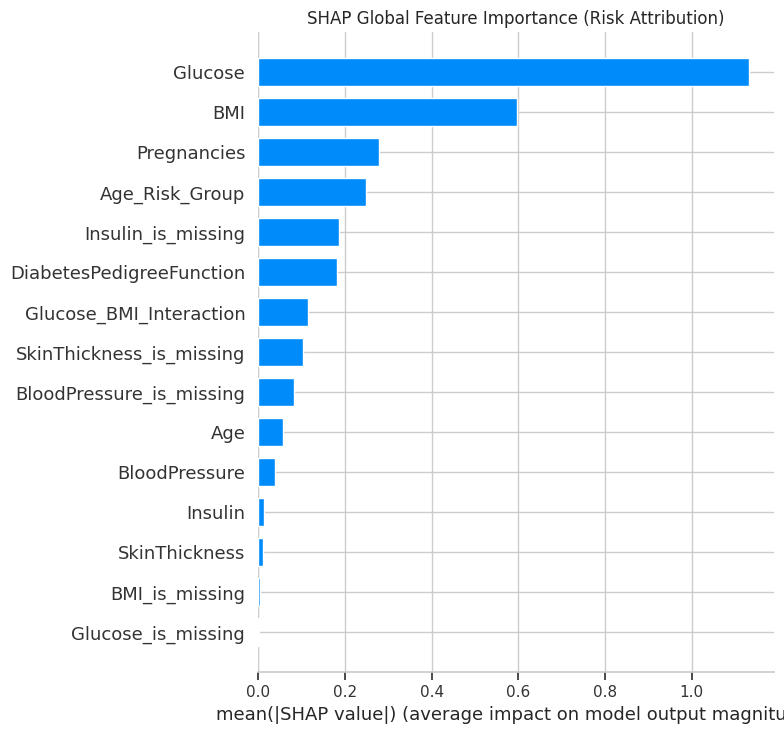

--- Generating SHAP Beewarm Plot ---


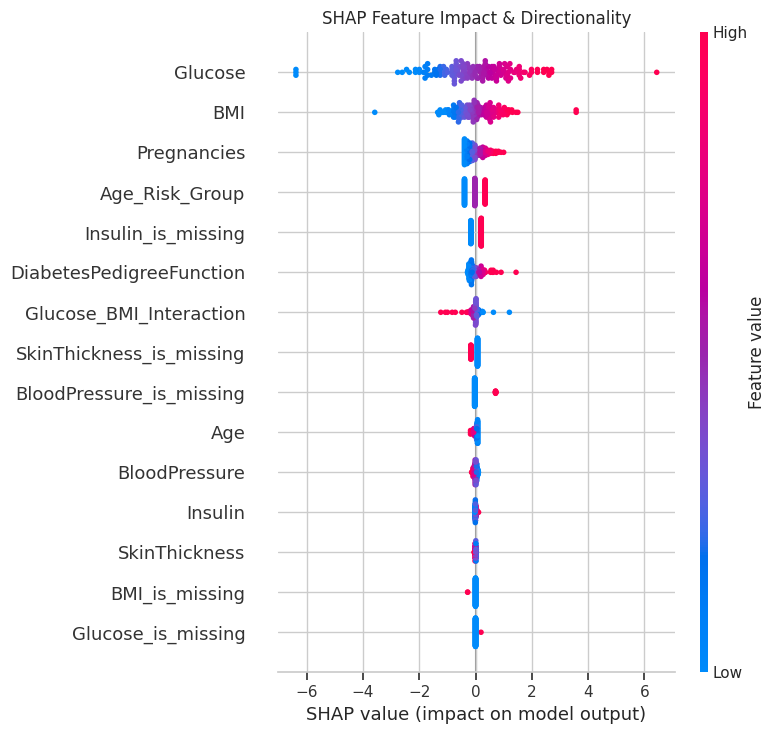


--- Pipeline Execution Fully Complete! ---
All data cleaning, MICE imputation, winsorization, feature engineering, baseline modeling, and SHAP visualizations have finished successfully.


In [6]:
# Model Interpretability (SHAP)

import shap

# 1. Initialize SHAP Linear Explainer for the trained baseline model
explainer = shap.LinearExplainer(baseline_model, X_train, feature_perturbation="interventional")
shap_values = explainer(X_test)

# 2. Generate Global Feature Importance Plot
print("--- Generating SHAP Feature Importance Plot ---")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance (Risk Attribution)")
plt.tight_layout()
plt.show()

# 3. Generate Detailed Beewarm Plot for Feature Directionality
print("--- Generating SHAP Beewarm Plot ---")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Feature Impact & Directionality")
plt.tight_layout()
plt.show()

print("\n--- Pipeline Execution Fully Complete! ---")
print("All data cleaning, MICE imputation, winsorization, feature engineering, baseline modeling, and SHAP visualizations have finished successfully.")